In [ ]:
import matplotlib.pyplot as plt
import pickle
import os
from warnings import warn

ROIS = [
"RMSE_whole_object",
"RMSE_background",
"AEM_VOI_sphere1",
"AEM_VOI_sphere3",
"AEM_VOI_sphere5",
]
algorithms = [ "SG", "SAG", "SAGA", "SVRG", "LSVRG", "SOS-SAGAfinal2"]
# algorithms = ['SAG', 'SAGA', 'SG', 'SVRG']
# algorithms = ['SOS-SAGAfinal2']
subsets = [21,42,63]
subsets = [42]
dataset = ['mMR_NEMA_lowcounts']

In [ ]:
# Open the file in read-binary mode
with open('allresults_lowcounts2.pkl', 'rb') as file:
    # Deserialize the dictionary from the file
    loaded_dict = pickle.load(file)

In [ ]:
# plot one algorithm WRT number of subsets
linestyles = ['solid', 'dotted', 'dashed', 'solid', 'dotted', 'dashed']
linecolors = ['C0', 'C1', 'C2', 'C3', 'C4', 'C5']
import pysnooper
# @pysnooper.snoop()
def _plot_it(data, algs: list, num_subsets, which, dataset="mMR_NEMA", linecolors=linecolors, linestyles=linestyles, 
             yscale='linear', figsize=None, xlim=None, legend_loc=None, savefig=False):
    """
    legend_loc: 'upper left', 'upper right', 'lower left', 'lower right'
    """
    plt.figure(figsize=figsize)
    if not isinstance(num_subsets, list):
        num_subsets = [num_subsets]
    for alg_idx, alg in enumerate(algs):
        for ns_idx,ns in enumerate(num_subsets):
            idx = f"{alg}_{dataset}_{ns}"
            # print (f"processing {idx}")
            algdata = data[idx]
            tmp = algdata['iteration_num']
            if which == 'objective':
                x = [ el/num_subsets[ns_idx] for el in algdata['iteration_num']]
                y = algdata['objective']
                xlabel = 'epoch'
            else:
                # why this has one more than the data passes?
                
                if alg in ["SAG", "SAGA"]:
                    x = algdata['data_passes']
                    # the last one is the one at 80 epochs
                    y = algdata[which][:-1]
                    # print (f"{alg} {len(x)} {len(y)}")
                elif alg == "SOS-SAGAfinal2":
                    # we do 5 full gradients in SOS but the number of data passes is not accounted
                    # for correctly
                    x = [el + 5 for el in algdata['data_passes'] ]
                    x = [1,2,3,4,5] + x
                    y = algdata[which][:-1]
                    
                elif alg in ['SVRG', 'LSVRG']:
                    x = algdata['data_passes']
                    # This failed regularly without the [1:]
                    y = algdata[which][:-1]
                    # print (f"{alg} {len(x)} {len(y)}")
                elif alg == 'SG':
                    x = algdata['data_passes']
                    # This failed regularly without removing one from the data
                    y = algdata[which][:-1]
                    # print (f"{alg} {len(x)} {len(y)}")
                # x = [el for el in range(len(y))]
                xlabel = 'data passes'
            
            #assert len(x) == len(y), f"{idx} {which}: len(x) != len(y) {len(x)}=!{len(y)} "
            if len(x) == len(y):
                ttl = f"{alg} {ns} subsets"
                ii = ns_idx + len(num_subsets) * alg_idx
                # print (f"{alg} ii {ii}, alg_idx {alg_idx} ns_idx {ns_idx}")
                fkwargs = {'linestyle': linestyles[ii] ,
                          'color': linecolors[ii]}
                        
                plt.plot(x,y, label=ttl, **fkwargs)
            else:
                warn(f"ERROR: {alg} {idx} {which}: len(x) != len(y) {len(x)}=!{len(y)} ")

    if legend_loc is not None:
        plt.legend(loc=legend_loc)
    plt.xlabel(xlabel)
    if xlim is not None:
        plt.xlim(xlim)
    plt.ylabel(which)
    plt.yscale(yscale)
    plt.title(which)
    if savefig:
        print("saving fig")
        gcf = plt.gcf()
        gcf.savefig(f"{which}_{num_subsets}.png", format='png')
    plt.show()
    
    

In [ ]:
_linestyles = ['solid', 'dotted', 'dashed']
_algos = algorithms
subsets = [21,42,63]

def get_linestyles(subsets, algos=_algos, linestyles=_linestyles):
    ls = []
    for algo in algos:
        for i,ds in enumerate(subsets):
            ls.append(linestyles[i])
    return ls

# linecolors = [f'C{i}' for i in [0,0,0,1,1,1,2,2,2,3,3,3,4,4,4,5,5,5]]
def get_linecolors(subsets, algos):
    lc = []
    for i,_ in enumerate(algos):
        for _ in subsets:
            lc.append(f'C{i}')
    return lc

# linestyles = get_linestyles(subsets)
# print (linestyles)
# print (get_linecolors(subsets, _algos))

In [ ]:
algos = [ "SG","SAG", "SAGA", "SVRG", "LSVRG", "SOS-SAGAfinal2"]
subsets = [42]
savefig = True
#"SG", "SAG", "SAGA", "SVRG", "LSVRG", 
_plot_it(loaded_dict, algos , subsets, 
         which='objective', dataset="mMR_NEMA_lowcounts",
         linestyles=get_linestyles(subsets, algos),
         linecolors=get_linecolors(subsets, algos), 
         figsize=(15,6), yscale="log", xlim=(0,80),
         legend_loc='upper right', savefig=savefig)

In [ ]:

#"SG", "SAG", "SAGA", "SVRG", "LSVRG", 
_plot_it(loaded_dict, _algos , subsets, 
         which=ROIS[0], dataset="mMR_NEMA_lowcounts",
         linestyles=get_linestyles(subsets, algos),
         linecolors=get_linecolors(subsets, algos), 
         figsize=(15,6), yscale="log", xlim=(0,30),
         legend_loc='lower left', savefig=savefig)

In [ ]:

#"SG", "SAG", "SAGA", "SVRG", "LSVRG", 
_plot_it(loaded_dict, _algos, subsets, 
         which=ROIS[1], dataset="mMR_NEMA_lowcounts",
         linestyles=get_linestyles(subsets, algos),
         linecolors=get_linecolors(subsets, algos),  figsize=(15,6), yscale="log", xlim=(0,40),
         legend_loc='lower left', savefig=savefig)

In [ ]:
_plot_it(loaded_dict, _algos, subsets, 
         which=ROIS[2], dataset="mMR_NEMA_lowcounts",
         linestyles=get_linestyles(subsets, algos),
         linecolors=get_linecolors(subsets, algos),  figsize=(15,6), yscale="log", xlim=(0,20),
         legend_loc='lower left', savefig=savefig)

In [ ]:
_plot_it(loaded_dict, _algos, subsets, 
         which=ROIS[3], dataset="mMR_NEMA_lowcounts",
         linestyles=get_linestyles(subsets, algos),
         linecolors=get_linecolors(subsets, algos),  figsize=(15,6), yscale="log", xlim=(0,20),
         legend_loc='lower left', savefig=savefig)

saving fig


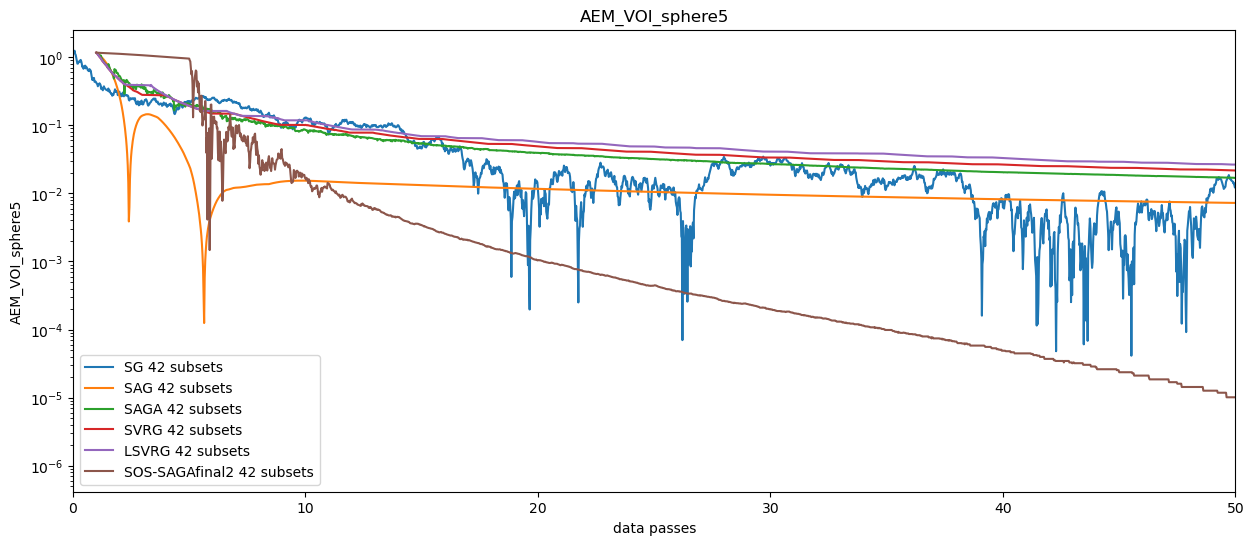

In [168]:
_plot_it(loaded_dict, _algos, subsets, 
         which=ROIS[4], dataset="mMR_NEMA_lowcounts",
         linestyles=get_linestyles(subsets, algos),
         linecolors=get_linecolors(subsets, algos),  figsize=(15,6), yscale="log", xlim=(0,50),
         legend_loc='lower left', savefig=savefig)

In [ ]:
algos = ['SAGA', "SOS-SAGAfinal2"]

#"SG", "SAG", "SAGA", "SVRG", "LSVRG", 
_plot_it(loaded_dict, _algos , subsets, 
         which=ROIS[0], dataset="mMR_NEMA_lowcounts",
         linestyles=get_linestyles(subsets, algos),
         linecolors=get_linecolors(subsets, algos), 
         figsize=(15,6), yscale="log", xlim=(0,30),
         legend_loc='lower left', savefig=savefig)